![Agentic RAG](../diagrams/18-agentic-rag.png)

![RAG pipeline](../diagrams/17-rag-basics.png)

### Agentic RAG
In Agentic RAG the LLM **decides** whether to call a retriever tool. Retrieved documents are graded: if relevant the answer is generated, otherwise the question is rewritten and the agent tries again.

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()  # loads OPENAI_API_KEY from .env

True

In [2]:
import requests
from bs4 import BeautifulSoup
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

def load_web_pages(urls: list[str]) -> list[Document]:
    """Download pages and keep only their readable text."""
    docs = []
    for url in urls:
        html = requests.get(url, timeout=30, headers={"User-Agent": "langgraph-teaching-notebooks/1.0"}).text
        soup = BeautifulSoup(html, "html.parser")
        for tag in soup(["script", "style", "nav", "footer", "header"]):
            tag.decompose()
        docs.append(Document(page_content=soup.get_text(separator="\n", strip=True), metadata={"source": url}))
    return docs

def build_retriever(urls: list[str], chunk_size: int = 500, chunk_overlap: int = 50):
    """Load -> split -> embed -> store in an in-memory vector store -> return a retriever."""
    splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    splits = splitter.split_documents(load_web_pages(urls))
    vectorstore = InMemoryVectorStore.from_documents(documents=splits, embedding=embeddings)
    return vectorstore.as_retriever()

#### Retriever 1: LangGraph docs

In [3]:
urls = [
    "https://docs.langchain.com/oss/python/langgraph/overview",
    "https://docs.langchain.com/oss/python/langgraph/workflows-agents",
    "https://docs.langchain.com/oss/python/langgraph/graph-api",
]
retriever = build_retriever(urls, chunk_size=1000, chunk_overlap=100)
retriever.invoke("what is langgraph")[:2]

[Document(id='0dafc381-d754-47c2-a7a8-feea9ad22340', metadata={'source': 'https://docs.langchain.com/oss/python/langgraph/overview'}, page_content='LangGraph overview - Docs by LangChain\nDocumentation Index\nFetch the complete documentation index at:\n/llms.txt\nUse this file to discover all available pages before exploring further.\nSkip to main content\nTrusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. LangGraph gives you fine-grained control to mix deterministic, hand-coded steps with LLM-driven agentic steps in the same graph, so you can build bespoke agents that behave exactly the way your application requires.\nLangGraph is very low-level, and focused entirely on agent\norchestration\n. Before using LangGraph, we recommend you familiarize yourself with some of the components used to build agents, starting 

#### Retriever to retriever tool

In [4]:
from langchain_core.tools import create_retriever_tool

retriever_tool = create_retriever_tool(
    retriever,
    "retriever_vector_db_blog",
    "Search and return information about LangGraph",
)
retriever_tool

StructuredTool(name='retriever_vector_db_blog', description='Search and return information about LangGraph', args_schema=<class 'langchain_core.tools.retriever.RetrieverInput'>, func=<function create_retriever_tool.<locals>.func at 0x0000024BB9CC3690>, coroutine=<function create_retriever_tool.<locals>.afunc at 0x0000024BBD259640>)

#### Retriever 2: LangChain docs (separate vector store)

In [5]:
langchain_urls = [
    "https://docs.langchain.com/oss/python/langchain/overview",
    "https://docs.langchain.com/oss/python/langchain/rag",
    "https://docs.langchain.com/oss/python/langchain/agents",
]
retriever_langchain = build_retriever(langchain_urls, chunk_size=1000, chunk_overlap=100)

retriever_tool_langchain = create_retriever_tool(
    retriever_langchain,
    "retriever_vector_langchain_blog",
    "Search and return information about LangChain",
)
tools = [retriever_tool, retriever_tool_langchain]

### LangGraph Workflow

In [6]:
from typing import Annotated, Literal, Sequence
from typing_extensions import TypedDict
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    # The add_messages reducer APPENDS new messages (the default would be to replace)
    messages: Annotated[Sequence[BaseMessage], add_messages]

In [7]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# (replaces the old hub.pull("rlm/rag-prompt"))
rag_prompt = ChatPromptTemplate.from_messages([
    ("human", """You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. If you don't know the answer, just say that you don't know. Use three sentences maximum and keep the answer concise.
Question: {question}
Context: {context}
Answer:"""),
])

def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

In [8]:
from pydantic import BaseModel, Field

llm = ChatOpenAI(model="gpt-4.1-mini", temperature=0)

def agent(state: AgentState):
    """
    Invokes the agent model to generate a response based on the current state. Given
    the question, it will decide to retrieve using the retriever tool, or simply end.
    """
    print("---CALL AGENT---")
    model = llm.bind_tools(tools)
    response = model.invoke(state["messages"])
    # We return a list, because this will get added to the existing list
    return {"messages": [response]}


### Edges
class Grade(BaseModel):
    """Binary score for relevance check."""

    binary_score: str = Field(description="Relevance score 'yes' or 'no'")

grader_prompt = ChatPromptTemplate.from_template(
    """You are a grader assessing relevance of a retrieved document to a user question.
Here is the retrieved document: \n\n {context} \n\n
Here is the user question: {question} \n
If the document contains keyword(s) or semantic meaning related to the user question, grade it as relevant.
Give a binary score 'yes' or 'no' score to indicate whether the document is relevant to the question."""
)
grader_chain = grader_prompt | llm.with_structured_output(Grade)

def grade_documents(state: AgentState) -> Literal["generate", "rewrite"]:
    """Determines whether the retrieved documents are relevant to the question."""
    print("---CHECK RELEVANCE---")
    messages = state["messages"]
    question = messages[0].content
    docs = messages[-1].content  # the ToolMessage holding the retrieved text

    scored_result = grader_chain.invoke({"question": question, "context": docs})
    if scored_result.binary_score == "yes":
        print("---DECISION: DOCS RELEVANT---")
        return "generate"
    print("---DECISION: DOCS NOT RELEVANT---")
    return "rewrite"


def generate(state: AgentState):
    """Generate the answer from the retrieved documents."""
    print("---GENERATE---")
    messages = state["messages"]
    question = messages[0].content
    docs = messages[-1].content

    rag_chain = rag_prompt | llm | StrOutputParser()
    response = rag_chain.invoke({"context": docs, "question": question})
    return {"messages": [AIMessage(content=response)]}  # AIMessage: a bare str would become a HumanMessage


def rewrite(state: AgentState):
    """Transform the query to produce a better question."""
    print("---TRANSFORM QUERY---")
    question = state["messages"][0].content
    msg = [HumanMessage(content=f"""
Look at the input and try to reason about the underlying semantic intent / meaning.
Here is the initial question:
-------
{question}
-------
Formulate an improved question: """)]
    response = llm.invoke(msg)
    # Return it as a new user question for the agent
    return {"messages": [HumanMessage(content=response.content)]}

#### Build the graph

In [9]:
from langgraph.graph import END, StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition

workflow = StateGraph(AgentState)

workflow.add_node("agent", agent)
workflow.add_node("retrieve", ToolNode([retriever_tool, retriever_tool_langchain]))
workflow.add_node("rewrite", rewrite)
workflow.add_node("generate", generate)

workflow.add_edge(START, "agent")

# Decide whether to retrieve
workflow.add_conditional_edges("agent", tools_condition, {"tools": "retrieve", END: END})

# After retrieval, grade the documents
workflow.add_conditional_edges("retrieve", grade_documents)
workflow.add_edge("generate", END)
workflow.add_edge("rewrite", "agent")

graph = workflow.compile()

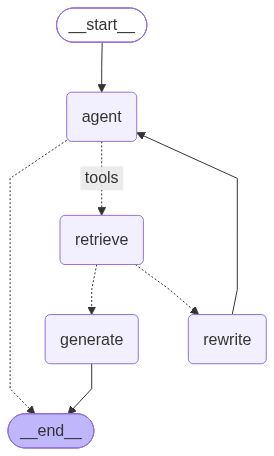

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
result = graph.invoke({"messages": "What is LangGraph?"})
result["messages"][-1].pretty_print()

---CALL AGENT---


---CHECK RELEVANCE---


---DECISION: DOCS RELEVANT---
---GENERATE---


================================== Ai Message ==================================

LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. It allows combining deterministic, hand-coded logic with LLM-driven steps in a single graph, providing fine-grained control over agent workflows with features like persistence, human-in-the-loop, and comprehensive memory. LangGraph is designed for durable execution, streaming, and debugging, and integrates well with LangChain products but can be used standalone.


In [12]:
result = graph.invoke({"messages": "What is LangChain?"})
result["messages"][-1].pretty_print()

---CALL AGENT---


---CHECK RELEVANCE---


---DECISION: DOCS RELEVANT---
---GENERATE---


================================== Ai Message ==================================

LangChain is a framework for building customizable agents and applications that integrate language models with tools and middleware. It provides a standard interface for various models, supports incremental capability additions, and is built on top of LangGraph for durable execution and advanced orchestration. LangChain also includes LangSmith for tracing, debugging, and evaluating agent behavior.


In [13]:
# Not related to the indexed docs -> the agent should answer directly without retrieving
result = graph.invoke({"messages": "What is Machine learning?"})
result["messages"][-1].pretty_print()

---CALL AGENT---


================================== Ai Message ==================================

Machine learning is a branch of artificial intelligence (AI) that focuses on developing algorithms and statistical models that enable computers to learn and make decisions or predictions based on data. Instead of being explicitly programmed to perform a task, machine learning systems improve their performance by identifying patterns and relationships in data through experience. It is widely used in various applications such as image recognition, natural language processing, recommendation systems, and autonomous vehicles.
